# Machine Learning Concepts

**Family:** Fundamentals | **Level:** Beginner | **Runs on:** CPU, under a minute

Overfitting, the bias variance trade-off, data leakage and validation.

## Learning objectives

- Detect overfitting with train and validation scores
- Run a validation curve
- See data leakage inflate a score
- Choose between hold out and cross validation

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ml_lab.data import load_dataset
from ml_lab.utils import set_seed
from ml_lab import visualization as viz
SEED = 42
set_seed(SEED)
viz.apply_style()

## 1. Overfitting

We fit polynomials of growing degree on a noisy sample of Auto MPG and compare training and validation error.

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
df = load_dataset("auto_mpg").frame
Xtr, Xva, ytr, yva = train_test_split(df[["horsepower"]].values, df["mpg"].values, test_size=0.3, random_state=SEED)
rows = []
for d in [1, 2, 3, 5, 8, 12]:
    m = make_pipeline(StandardScaler(), PolynomialFeatures(d), LinearRegression()).fit(Xtr, ytr)
    rows.append({"degree": d, "train_rmse": mean_squared_error(ytr, m.predict(Xtr)) ** 0.5, "validation_rmse": mean_squared_error(yva, m.predict(Xva)) ** 0.5})
display(pd.DataFrame(rows).set_index("degree").round(3))

,train_rmse,validation_rmse
degree,,
1,4.892,4.955
2,4.311,4.522
3,4.300,4.538
5,4.266,4.442
8,4.227,4.587
12,4.196,5.106


## 2. Data leakage

We use the breast cancer data with 500 noise features. Selecting the best features on all rows before splitting makes pure noise look predictive.

In [3]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
rng = np.random.default_rng(SEED)
Xn, yn = rng.normal(size=(100, 500)), rng.integers(0, 2, 100)      # labels are random
leak = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)
print("leaky: select features on all rows, then cross validate:", round(cross_val_score(LogisticRegression(), leak, yn, cv=5).mean(), 3))
pipe = make_pipeline(SelectKBest(f_classif, k=10), LogisticRegression())
print("correct: selection inside each fold:", round(cross_val_score(pipe, Xn, yn, cv=5).mean(), 3), "(chance is about 0.5)")

leaky: select features on all rows, then cross validate: 0.79
correct: selection inside each fold: 0.56 (chance is about 0.5)


## 3. Learning curve

More data helps only if the model has not reached its limit.

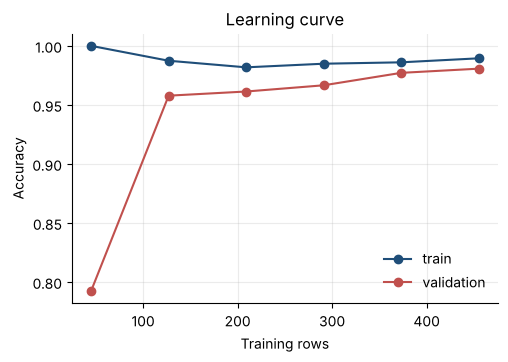

In [4]:
from sklearn.model_selection import learning_curve
bc = load_dataset("breast_cancer")
sizes, tr, va = learning_curve(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), bc.X, bc.y, cv=5, train_sizes=np.linspace(0.1, 1, 6), random_state=SEED)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(sizes, tr.mean(axis=1), marker="o", label="train"); ax.plot(sizes, va.mean(axis=1), marker="o", label="validation")
ax.set_xlabel("Training rows"); ax.set_ylabel("Accuracy"); ax.legend(); ax.set_title("Learning curve"); plt.show()

## 4. Hold out versus cross validation

In [5]:
from sklearn.model_selection import KFold
X, y = df[["weight", "horsepower", "model_year"]], df["mpg"]
for k in [3, 5, 10]:
    s = cross_val_score(LinearRegression(), X, y, cv=KFold(k, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error")
    print(f"{k}-fold RMSE {-s.mean():.3f} +- {s.std(ddof=1):.3f}")

3-fold RMSE 3.472 +- 0.561
5-fold RMSE 3.433 +- 0.442
10-fold RMSE 3.412 +- 0.601


## Exercises

1. Repeat the leakage demo with 5000 features and report how the leaky score changes.
2. Plot a validation curve for k in KNN on the wine data.

## Summary

- Training error alone misleads.
- Leakage can make noise look like signal.
- Cross validation reports spread.

**Next:** Feature engineering.

**Data note.** Real datasets come from `ml_lab.data` with licence notes in `datasets/catalog`. Synthetic numbers appear only where a demonstration needs controlled data, and are labelled.